# Experiment 18: RNN, LSTM and GRU Hyperparameter Experimentation

A product team classifies reviews as positive or negative and compares recurrent cell types under a compute budget. We create short token sequences with positive/negative sentiment cues, then use KerasTuner when installed or a small reproducible grid fallback.

**Tools:** TensorFlow, Keras, NumPy, KerasTuner, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Tokenise/pad review sequences and add an embedding layer.  2. Build a model selector for SimpleRNN, LSTM or GRU.  3. Tune units, layer count, dropout, learning rate and embedding size.  4. Report the best configuration per cell type.  5. Compare accuracy, parameter count and training time.

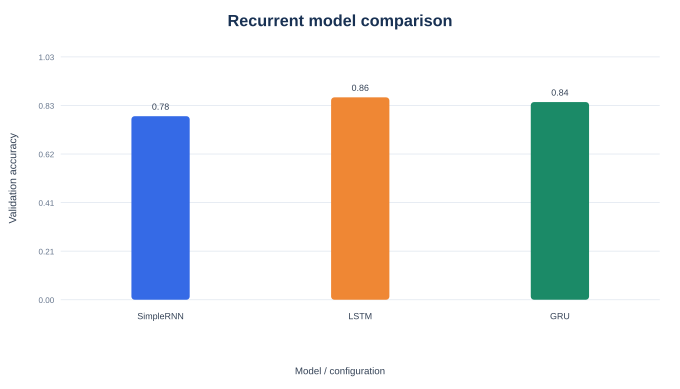

In [ ]:
import numpy as np
import pandas as pd
import time
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences

tf.keras.utils.set_random_seed(18)
rng=np.random.default_rng(18)
vocab_size=500; max_len=40; n=1600
X=np.zeros((n,max_len),dtype="int32"); y=np.arange(n)%2
for i in range(n):
    base=rng.integers(5,vocab_size,size=max_len)
    cue=2 if y[i] else 3
    base[:rng.integers(2,7)]=cue
    X[i]=base
X=pad_sequences(X,maxlen=max_len,padding="post",truncating="post")
perm=rng.permutation(n);X=X[perm];y=y[perm]
split=int(.8*n);Xtr,Xte=X[:split],X[split:];ytr,yte=y[:split],y[split:]
cell_types=["SimpleRNN","LSTM","GRU"]
results=[]

def build_model(cell_type, units=32, layers=1, dropout=.2, embed_dim=24, lr=.001):
    inputs=tf.keras.Input((max_len,))
    x=tf.keras.layers.Embedding(vocab_size,embed_dim,mask_zero=True)(inputs)
    Cell={"SimpleRNN":tf.keras.layers.SimpleRNN,"LSTM":tf.keras.layers.LSTM,"GRU":tf.keras.layers.GRU}[cell_type]
    for _ in range(layers-1): x=Cell(units,return_sequences=True,dropout=dropout)(x)
    x=Cell(units,dropout=dropout)(x)
    outputs=tf.keras.layers.Dense(1,activation="sigmoid")(x)
    m=tf.keras.Model(inputs,outputs)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss="binary_crossentropy",metrics=["accuracy"])
    return m

try:
    import keras_tuner as kt
    tuner_available=True
except ImportError:
    tuner_available=False

for cell_type in cell_types:
    best=None
    if tuner_available:
        class ReviewHyperModel(kt.HyperModel):
            def build(self,hp):
                return build_model(cell_type,
                    units=hp.Choice("units",[16,32,48]),
                    layers=hp.Choice("layers",[1,2]),
                    dropout=hp.Choice("dropout",[.1,.3,.5]),
                    embed_dim=hp.Choice("embedding_dim",[16,24,32]),
                    lr=hp.Choice("learning_rate",[1e-3,3e-4]))
        tuner=kt.RandomSearch(ReviewHyperModel(),objective="val_accuracy",
            max_trials=3,overwrite=True,directory="kt_experiments",project_name=cell_type)
        tuner.search(Xtr,ytr,validation_split=.2,epochs=3,batch_size=32,verbose=0)
        best=tuner.get_best_models(1)[0]
        best_hp=tuner.get_best_hyperparameters(1)[0].values
    else:
        candidates=[{"units":u,"layers":l,"dropout":d,"embed_dim":e,"lr":lr}
                    for u,l,d,e,lr in [(16,1,.2,16,.001),(32,1,.3,24,.001),(32,2,.2,32,.0005)]]
        best_score=-1
        for cfg in candidates:
            candidate=build_model(cell_type,**cfg)
            candidate.fit(Xtr,ytr,validation_split=.2,epochs=3,batch_size=32,verbose=0)
            val_size=int(.2*len(Xtr))
            score=candidate.evaluate(Xtr[-val_size:],ytr[-val_size:],verbose=0)[1]
            if score>best_score:best,best_hp,best_score=candidate,cfg,score
    start=time.perf_counter()
    h=best.fit(Xtr,ytr,validation_split=.15,epochs=4,batch_size=32,verbose=0)
    seconds=time.perf_counter()-start
    _,acc=best.evaluate(Xte,yte,verbose=0)
    results.append({"cell":cell_type,"best config":str(best_hp),"test accuracy":acc,
                    "parameters":best.count_params(),"final val accuracy":max(h.history["val_accuracy"]),
                    "training seconds":seconds})
print(pd.DataFrame(results).round(3).to_string(index=False))
print("KerasTuner used:",tuner_available)